# Neural Galerkin method for solving spatio-temporal PDEs

In this notebook, we illustrate the Neural Galerkin approach that is implemented in `jinns` and accessible via the `solve_neural_galerkin` function. Using this function requires however some small changes in the traditional `jinns` workflow. We provide two examples here on the Fisher KPP equation in 1D and on the Heat equation in 2D.

The mathematical background of this approach is detailed [here](https://mia_jinns.gitlab.io/jinns/api/solve/solve_neural_galerkin/) in the jinns documentation.

Roughly, the Neural Galerkin aproach first fits the initial condition and iteratively estimates the solution for subsequent time steps by solving an ODE on the parameters.

Hence, the **main differences** with the classical spatio-temporal workflow are:

1. the (`jinns`) objects (DataGenerators, Losses, PINN, etc.) are **defined as in the stationary case** although we solve a spatio-temporal PDE.
2. the **boundary conditions must be hardcoded**.
3. at the end of the optimization, we get **a set of Params objects (each for a stationary PINN, see 1.) at each queried times**.

We comment on those differences in the two following examples.

## Fisher KPP in 1D

The PDE reads

$$
\begin{cases}
\frac{\partial}{\partial t} u(t,x)=D\frac{\partial^2}{\partial x^2} u(t,x) + u(t,x)(r - \gamma u(t,x)), t\geq 0, x\in [0,l]\\
\begin{cases}
u(t,0)=u(t,l)=0,t\geq 0, \text{Dirichlet condition}\\
\frac{\partial u(t,x)}{\partial n}\Big|_{x\in\{0,l\}}=\frac{\partial}{\partial x} u(t,x)\cdot n=0, t\geq0,\text{Neumann condition},
\end{cases}\\
u(0,x)=u_0(x),x\in [0,l]
\end{cases}
$$

$r$, $\gamma$ et $D$ are constant.
For more details on this PDE, see the [Fisher KPP 1D notebook](https://mia_jinns.gitlab.io/jinns/Notebooks/PDE/1D_non_stationary_Fisher_KPP_Bounded_Domain/).

In [18]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [19]:
import os

os.environ["JAX_PLATFORMS"] = "cpu"

In [20]:
import jax

jax.config.update("jax_enable_x64", True)

In [21]:
from jax import random, vmap
import jax.numpy as jnp
import equinox as eqx
import matplotlib.pyplot as plt


key = random.PRNGKey(2)

In [22]:
import jinns

In [23]:
# Here we define the model parameters that will remain fixed in all the problem
D = 1.0
r = 3.0
g = 3.0

We now define the time discretization for solving the EDO on the parameters (see more details [here](https://mia_jinns.gitlab.io/jinns/api/solve/solve_neural_galerkin/)). Finer resolution will lead to more accurate solutions but will be more expensive to compute.

`tmin` and `tmax` here define the time interval on which we want to solve the PDE.

In [24]:
tmin = 0.0
tmax = 5.0
dt = 0.005
times = jnp.arange(tmin, tmax + dt, dt)
print(len(times), times)

1001 [0.    0.005 0.01  ... 4.99  4.995 5.   ]


As mentioned in the introduction, the boundary condition must be hardcoded. There exists in the PINN literature several approaches. Here we implement the two most common approach for Neumann and Dirichlet boundary conditions.

- We implement **fourier frequency embedding** (https://arxiv.org/pdf/2504.01093v1) as an `input_transform` in order to hard constraint Neumann BC.
- Implementation of hard constraint for Dirichlet BC is much more straightforward using an `output_transform`.

In [25]:
def input_transform(x, params):
    """
    x is the PINN input
    this is for Neumann
    """
    return jnp.array([jnp.cos(jnp.pi * (x[0] - xmin) / (xmax - xmin))])


def output_transform(x, pinn_out, params):
    """
    this is for Dirichlet
    """
    return (x[0] - xmin) * (x[0] - xmax) * pinn_out

Next we define the PINN. As we said, a **stationary PINN** must be instanciated.

In [26]:
eqx_list = (
    (eqx.nn.Linear, 1, 16),
    (jax.nn.tanh,),
    (eqx.nn.Linear, 16, 16),
    (jax.nn.tanh,),
    (eqx.nn.Linear, 16, 1),
)
key, subkey = random.split(key)
u_pinn, init_nn_params_pinn = jinns.nn.PINN_MLP.create(
    key=subkey,
    eqx_list=eqx_list,
    eq_type="PDEStatio",
    output_transform=output_transform,  # for Dirichlet BC
    # input_transform=input_transform # for Neumann BC
)
init_params_pinn = jinns.parameters.Params(
    nn_params=init_nn_params_pinn,
    eq_params={
        "D": jnp.array([D]),
        "r": jnp.array([r]),
        "g": jnp.array([g]),
    },
)

Next we define the DataGenerator. The DataGenerator also only implements the space domain, as is we were solving a stationary problem.

In [27]:
n = 2048
batch_size = 256
dim = 1
xmin = -1
xmax = 1
method = "uniform"

key, subkey = random.split(key)
train_data = jinns.data.CubicMeshPDEStatio(
    key=subkey,
    n=n,
    omega_batch_size=batch_size,
    dim=dim,
    min_pts=(xmin,),
    max_pts=(xmax,),
    method=method,
)

Next we define the initial condition that will be fit first to get the initial set of parameters.

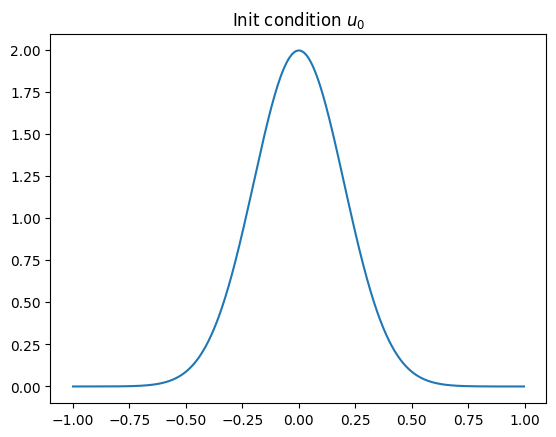

In [28]:
from jax.scipy.stats import norm

# Initial condition N(0,1)
sigma_init = 0.2 * jnp.ones((1))
mu_init = 0 * jnp.ones((1))


def u0(x):
    return jnp.squeeze(norm.pdf(x, loc=mu_init, scale=sigma_init))


plt.plot(
    train_data.omega.sort(axis=0),
    vmap(u0, (0), 0)(train_data.omega.sort(axis=0)),
)
plt.title(r"Init condition $u_0$")
plt.show()

Next we defined the dynamic loss without the time component, as if in the stationary case.

In [29]:
class FisherKPP_statio(jinns.loss.PDEStatio):
    """
    This implements the RHS of the equation of the top of the notebook
    """

    def equation(self, x, u, params):
        r"""
        Evaluate the dynamic loss at $x$.

        Parameters
        ---------
        x
            A jnp array a point in $\Omega$
        u
            The PINN
        params
            The dictionary of parameters of the model.
            Typically, it is a dictionary of
            dictionaries: `eq_params` and `nn_params`, respectively the
            differential equation parameters and the neural network parameter
        """
        lap = jinns.loss.laplacian_rev(x, u, params)[..., None]

        return -(
            params.eq_params.D * lap
            + u(x, params) * (params.eq_params.r - params.eq_params.g * u(x, params))
        )


fisher_dynamic_loss = FisherKPP_statio()

Accordingly, the main loss object is a `LossPDEStatio`.

In [30]:
loss_pinn = jinns.loss.LossPDEStatio(
    u=u_pinn,
    dynamic_loss=fisher_dynamic_loss,
    params=init_params_pinn,
)

/home/hugo/Documents/recherche/pinn/gitlab/jinns/loss/_LossPDE.py:128: UserWarning: Missing boundary condition.
  warnings.warn("Missing boundary condition.")


We define the time slices (elements of `times`) at which we want to save the parameters for subsequent PINN evaluations.

In [43]:
times_saved = [0.0, 0.1, 1.0, 4.0, 5.0]

The first training step consists in fitting the initial condition. The user must define the optimizer and the number of iterations for this step. **It is crucial that the initial condition be well fitted by the neural network** or errors will rapidly propagate in the parameter updates of the Neural Galerkin scheme.

On this simple 1D problem, 10000 Adam steps are enough though.

In [44]:
import optax

n_iter_ic = 10000
optimizer_ic = optax.adam(1e-3)

Now we are set for the call to `jinns.solve_neural_galerkin` !

In [45]:
_, _, _, params_final, params_saved = jinns.solve_neural_galerkin(
    times=times,
    times_saved=times_saved,
    init_params=init_params_pinn,
    data=train_data,
    loss=loss_pinn,
    initial_condition_fun=u0,
    n_iter_ic=n_iter_ic,
    optimizer_ic=optimizer_ic,
    print_loss_every=len(times) // 10,
)

Initialization time: 7.605552673339844e-05


 #-- Fitting the initial condition for t0= 0.0
Initialization time: 0.015859365463256836

Compilation took
 0.44914770126342773 

[train] Iteration 0: loss value = 0.4033472278500736
[train] Iteration 1000: loss value = 0.00020026333977130566
[train] Iteration 2000: loss value = 8.683686311352857e-05
[train] Iteration 3000: loss value = 3.804647351164233e-05
[train] Iteration 4000: loss value = 1.4274595695247662e-05
[train] Iteration 5000: loss value = 3.54381075952625e-06
[train] Iteration 6000: loss value = 1.0307721984347882e-06
[train] Iteration 7000: loss value = 8.349305700242752e-07
[train] Iteration 8000: loss value = 3.992621616812432e-07
[train] Iteration 9000: loss value = 3.263239409019757e-07

Stopping main optimization loop, cause: max iteration is reached

Training took
 1.9655132293701172 


Final iteration 10000: train loss value = 6.68330147628532e-07


 #-- Solving the parameters' ODE.

Compilation took
 0.717039585113525

We set up a plotting function for plotting the PINN at each time step for which we have saved the parameters

In [ ]:
def plot1d_slice_NG(
    fun_list, xdata, time_slices, Tmax, title="", figsize=(5, 5), ax=None
):
    """
    We must have len(fun_list) == len(time_slices)

    Parameters
    ----------
    fun_list
        a list of stationary PINNs (with signature f: R -> R) approximating the solution for each time slice
        in `time_slices`
    xdata
        the discretization of space
    time_slices
        the time slices :math:`t_i` at which to plot.
    Tmax
        Useful if you used time re-scaling in the differential equation, by
        default 1
    title
        title of the plot, by default ""
    figsize
        size of the figure, by default (10, 10)
    spinn
        True if a SPINN is to be plotted. False for PINNs and HyperPINNs
    ax
        A pre-defined `matplotlib.Axes` where you want to plot.

    Returns
    -------
    ax
        A `matplotlib.Axes` object
    """
    if time_slices is None:
        time_slices = jnp.array([0])
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)

    for idx, t in enumerate(time_slices):
        # fix t with partial : shape is (1,)
        v_u_tfixed = vmap(fun_list[idx])
        # add an axis to xdata for the concatenate function in the neural net
        values = v_u_tfixed(xdata)
        ax.plot(xdata, values, label=f"$t_i={t:.4f}$")
    ax.set_xlabel("x")
    ax.set_ylabel(r"$u(t_i, x)$")
    ax.legend()
    ax.set_title(title)
    return ax

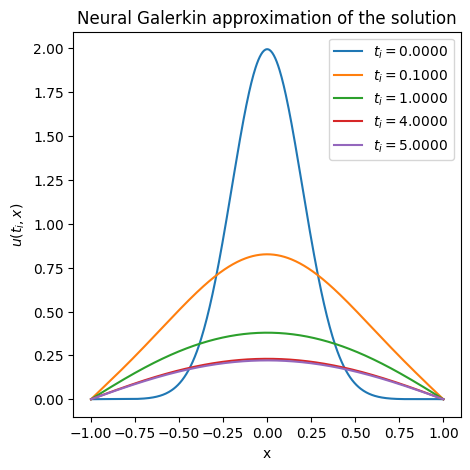

In [37]:
from functools import partial

u_est_pinn_at_times = [
    partial(u_pinn, params=p) for p in params_saved
]  # Note cannot use lambda here (classical mistake)

nx = 500
val_xdata = jnp.linspace(xmin, xmax, nx)

plot1d_slice_NG(
    u_est_pinn_at_times,
    xdata=val_xdata,
    time_slices=times_saved,
    Tmax=tmax,
    figsize=(5, 5),
    title="Neural Galerkin approximation of the solution",
)
plt.show()

This results as accurate as the result of the classical optimization made in the [Fisher KPP 1D notebook](https://mia_jinns.gitlab.io/jinns/Notebooks/PDE/1D_non_stationary_Fisher_KPP_Bounded_Domain/).

## Heat equation in 2D

The PDE reads